**⚠️ Not directly shareable — setup needed first:** open in Google Colab, get a free Groq API key from console.groq.com, then click Runtime → Run all. Paste the key when asked, then upload your CSV or Excel file (columns: Date, Category, Description, Amount, Type) or cancel the upload to use the built-in sample data (3 months).

# AI Personal Finance Tracker — Track Income and Expenses, Get Spending Insights

**Project | AI Mini Projects Series**

**Problem:** Most people do not know where their money goes each month.

**What this notebook does:** It reads your income and expenses, shows monthly savings, a category pie chart and charts by month, compares this month with last month, checks a simple budget, and an AI writes spending insights and tips in simple words.

**How it works:** CSV/Excel → clean data → monthly summary → category analysis → charts → facts → LLM insights.

**Tools:** Python, pandas, matplotlib, Groq (openai/gpt-oss-120b), Google Colab

## Step 1: Install libraries

In [1]:
!pip install -q pandas matplotlib openai openpyxl

## Step 2: Enter Groq key

In [2]:
import os
import getpass
from openai import OpenAI

os.environ["GROQ_API_KEY"] = getpass.getpass("Enter your Groq API key: ")

client = OpenAI(
    api_key=os.environ["GROQ_API_KEY"],
    base_url="https://api.groq.com/openai/v1"
)
model_name = "openai/gpt-oss-120b"
print("Groq client ready")

Enter your Groq API key: ··········
Groq client ready


## Step 3: Helper function to call the LLM

In [3]:
def ask_llm(system_msg, user_msg, temperature=0.3):
    try:
        response = client.chat.completions.create(
            model=model_name,
            messages=[
                {"role": "system", "content": system_msg},
                {"role": "user", "content": user_msg}
            ],
            temperature=temperature
        )
        return response.choices[0].message.content
    except Exception as e:
        return "Error calling Groq: " + str(e)

## Step 4: Load your data (or make sample data)
Your file needs these columns: `Date`, `Category`, `Description`, `Amount`, `Type` (Income or Expense).

In [4]:
import random
import pandas as pd
import matplotlib.pyplot as plt

df = None

try:
    from google.colab import files
    print("Upload your CSV or Excel file now (cancel to use sample data)")
    uploaded = files.upload()
    if len(uploaded) > 0:
        file_name = list(uploaded.keys())[0]
        if file_name.lower().endswith(".csv"):
            df = pd.read_csv(file_name)
        else:
            df = pd.read_excel(file_name)
except Exception as e:
    print("Upload not available, using sample data")

def split_amount(total, n):
    cuts = sorted([random.randint(1, total - 1) for i in range(n - 1)])
    parts = []
    last = 0
    for cut in cuts + [total]:
        parts.append(cut - last)
        last = cut
    return parts

if df is None:
    print("Making sample data for 3 months")
    random.seed(7)
    rows = []
    month_plan = {
        "2026-07": {"Food": 7600, "Travel": 4200, "Shopping": 5200, "Entertainment": 1500},
        "2026-08": {"Food": 8000, "Travel": 4500, "Shopping": 6000, "Entertainment": 2000},
        "2026-09": {"Food": 9600, "Travel": 4500, "Shopping": 7000, "Entertainment": 2500}
    }
    for month in month_plan:
        rows.append([month + "-01", "Salary", "Monthly salary", 50000, "Income"])
        rows.append([month + "-03", "Rent", "House rent", 12000, "Expense"])
        rows.append([month + "-10", "Bills", "Electricity and internet", 3000, "Expense"])
        for category in month_plan[month]:
            parts = split_amount(month_plan[month][category], 4)
            for p in parts:
                day = random.randint(2, 28)
                date_text = month + "-" + str(day).zfill(2)
                rows.append([date_text, category, category + " spend", p, "Expense"])
    df = pd.DataFrame(rows, columns=["Date", "Category", "Description", "Amount", "Type"])
    df.to_csv("sample_finance_data.csv", index=False)

print(df.head())
print("Total rows:", len(df))

Upload your CSV or Excel file now (cancel to use sample data)


Saving Finance_Sample_Test.csv to Finance_Sample_Test.csv
         Date  Category     Description  Amount     Type
0  2026-08-01    Salary  Monthly salary   42000   Income
1  2026-08-02      Rent      House rent   10000  Expense
2  2026-08-03    Travel    Travel spend      31  Expense
3  2026-08-03    Travel    Travel spend      61  Expense
4  2026-08-04  Shopping  Shopping spend     715  Expense
Total rows: 70


## Step 5: Clean the data

In [5]:
needed = ["Date", "Category", "Description", "Amount", "Type"]
missing = []
for col in needed:
    if col not in df.columns:
        missing.append(col)

if len(missing) > 0:
    print("These columns are missing:", missing)
    print("Please rename your columns and run again")
else:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
    df["Amount"] = pd.to_numeric(df["Amount"], errors="coerce")
    df["Type"] = df["Type"].astype(str).str.strip().str.title()
    df = df.dropna(subset=["Date", "Amount"])
    df["Month"] = df["Date"].dt.strftime("%Y-%m")
    print("Rows after cleaning:", len(df))
    print("Months found:", sorted(df["Month"].unique()))

Rows after cleaning: 70
Months found: ['2026-08', '2026-09', '2026-10']


## Step 6: Monthly summary — income, expenses and savings

         Income  Expense  Savings  Savings %
Month                                       
2026-08   42000    28100    13900       33.1
2026-09   48000    29800    18200       37.9
2026-10   42000    31000    11000       26.2


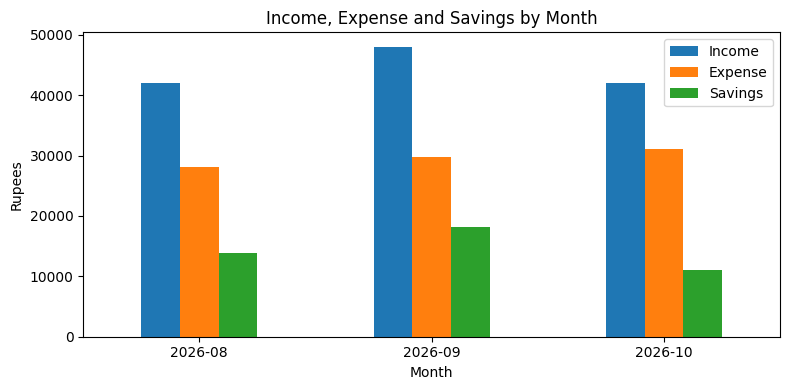

In [6]:
income = df[df["Type"] == "Income"].groupby("Month")["Amount"].sum()
expense = df[df["Type"] == "Expense"].groupby("Month")["Amount"].sum()

summary = pd.DataFrame({"Income": income, "Expense": expense}).fillna(0)
summary["Savings"] = summary["Income"] - summary["Expense"]
summary["Savings %"] = (summary["Savings"] / summary["Income"] * 100).round(1)

print(summary)

summary[["Income", "Expense", "Savings"]].plot(kind="bar", figsize=(8, 4))
plt.title("Income, Expense and Savings by Month")
plt.ylabel("Rupees")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("monthly_summary.png")
plt.show()

## Step 7: Where does the money go? (latest month)

Latest month: 2026-10
Category
Rent             10000
Food              9000
Shopping          4800
Travel            3200
Bills             2600
Entertainment     1400
Name: Amount, dtype: int64


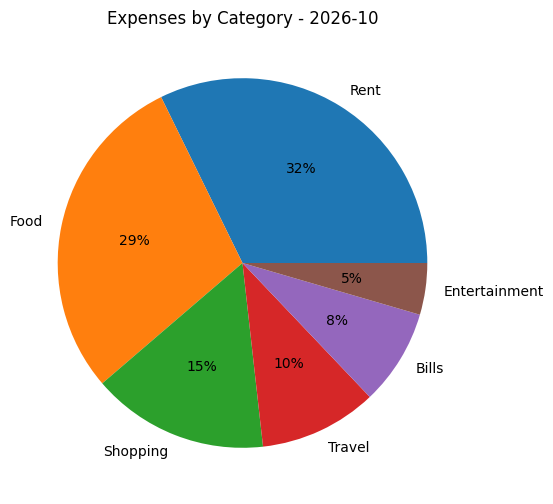

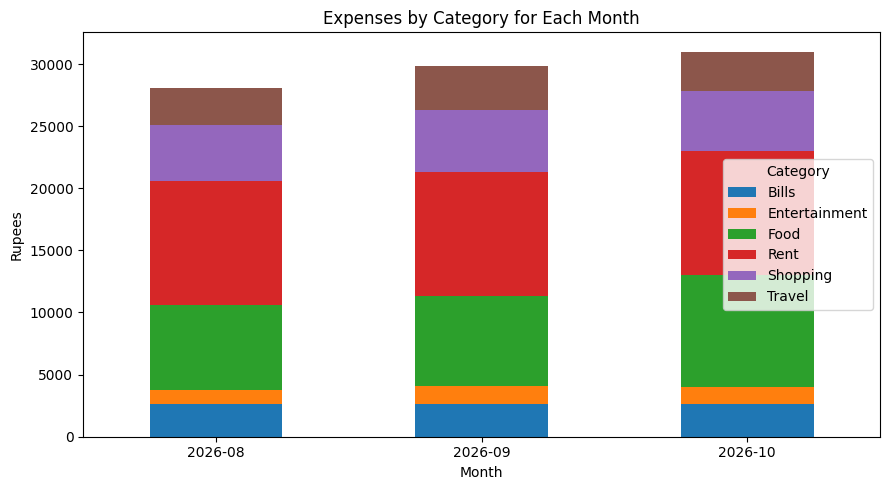

In [7]:
months = sorted(df["Month"].unique())
latest = months[-1]

expenses = df[df["Type"] == "Expense"]
latest_cat = expenses[expenses["Month"] == latest].groupby("Category")["Amount"].sum().sort_values(ascending=False)

print("Latest month:", latest)
print(latest_cat)

plt.figure(figsize=(6, 6))
plt.pie(latest_cat.values, labels=latest_cat.index, autopct="%1.0f%%")
plt.title("Expenses by Category - " + latest)
plt.savefig("category_pie.png")
plt.show()

pivot = expenses.pivot_table(index="Month", columns="Category", values="Amount", aggfunc="sum").fillna(0)
pivot.plot(kind="bar", stacked=True, figsize=(9, 5))
plt.title("Expenses by Category for Each Month")
plt.ylabel("Rupees")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("category_by_month.png")
plt.show()

## Step 8: Compare with last month and check budget

In [8]:
facts = []

if len(months) >= 2:
    last_month = months[-2]
    this_cat = expenses[expenses["Month"] == latest].groupby("Category")["Amount"].sum()
    prev_cat = expenses[expenses["Month"] == last_month].groupby("Category")["Amount"].sum()
    change = pd.DataFrame({"Last month": prev_cat, "This month": this_cat}).fillna(0)
    change["Change"] = change["This month"] - change["Last month"]
    change["Change %"] = (change["Change"] / change["Last month"].replace(0, 1) * 100).round(1)
    print(change.sort_values("Change %", ascending=False))

    biggest = change["Change %"].idxmax()
    facts.append("Biggest increase: " + biggest + " went up " + str(change.loc[biggest, "Change %"]) + "% compared to " + last_month)

budget = {"Food": 8000, "Travel": 5000, "Shopping": 6000, "Entertainment": 2000, "Bills": 3500, "Rent": 12000}

print("\nBudget check for", latest)
for cat in budget:
    spent = 0
    if cat in latest_cat.index:
        spent = latest_cat[cat]
    if spent > budget[cat]:
        text = cat + ": spent " + str(int(spent)) + " of " + str(budget[cat]) + " - OVER by " + str(int(spent - budget[cat]))
        facts.append("Over budget in " + cat + " by " + str(int(spent - budget[cat])) + " rupees in " + latest)
    else:
        text = cat + ": spent " + str(int(spent)) + " of " + str(budget[cat]) + " - ok"
    print(text)

top_cat = latest_cat.index[0]
facts.append("Biggest expense category in " + latest + ": " + top_cat + " (" + str(int(latest_cat.iloc[0])) + " rupees)")
facts.append("Savings in " + latest + ": " + str(int(summary.loc[latest, "Savings"])) + " rupees (" + str(summary.loc[latest, "Savings %"]) + "% of income)")

if len(months) >= 2:
    prev_month = months[-2]
    prev_income = int(summary.loc[prev_month, "Income"])
    this_income = int(summary.loc[latest, "Income"])
    prev_expense = int(summary.loc[prev_month, "Expense"])
    this_expense = int(summary.loc[latest, "Expense"])
    income_change = this_income - prev_income
    expense_change = this_expense - prev_expense
    savings_change = int(summary.loc[latest, "Savings"] - summary.loc[prev_month, "Savings"])

    facts.append("Income in " + prev_month + ": " + str(prev_income) + " rupees, in " + latest + ": " + str(this_income) + " rupees (change " + str(income_change) + ")")
    facts.append("Expenses in " + prev_month + ": " + str(prev_expense) + " rupees, in " + latest + ": " + str(this_expense) + " rupees (change " + str(expense_change) + ")")
    facts.append("Savings changed by " + str(savings_change) + " rupees from " + prev_month + " to " + latest)

    reasons = []
    if income_change < 0:
        reasons.append("income fell by " + str(-income_change))
    if income_change > 0:
        reasons.append("income rose by " + str(income_change))
    if expense_change > 0:
        reasons.append("expenses rose by " + str(expense_change))
    if expense_change < 0:
        reasons.append("expenses fell by " + str(-expense_change))
    if len(reasons) > 0:
        facts.append("Reason for the savings change: " + " and ".join(reasons))
    if abs(income_change) > abs(expense_change):
        facts.append("The bigger cause of the savings change is income")
    elif abs(expense_change) > abs(income_change):
        facts.append("The bigger cause of the savings change is expenses")

print("\nFacts worked out by pandas (these go to the AI):")
for f in facts:
    print("-", f)

               Last month  This month  Change  Change %
Category                                               
Food                 7200        9000    1800      25.0
Bills                2600        2600       0       0.0
Rent                10000       10000       0       0.0
Shopping             5000        4800    -200      -4.0
Entertainment        1500        1400    -100      -6.7
Travel               3500        3200    -300      -8.6

Budget check for 2026-10
Food: spent 9000 of 8000 - OVER by 1000
Travel: spent 3200 of 5000 - ok
Shopping: spent 4800 of 6000 - ok
Entertainment: spent 1400 of 2000 - ok
Bills: spent 2600 of 3500 - ok
Rent: spent 10000 of 12000 - ok

Facts worked out by pandas (these go to the AI):
- Biggest increase: Food went up 25.0% compared to 2026-09
- Over budget in Food by 1000 rupees in 2026-10
- Biggest expense category in 2026-10: Rent (10000 rupees)
- Savings in 2026-10: 11000 rupees (26.2% of income)
- Income in 2026-09: 48000 rupees, in 2026-10: 42

## Step 9: AI insights
The numbers and the reason why savings changed are worked out with pandas. The AI only puts them into words, but it can still word something wrong, so read the insights. A small check afterwards lists any number in the AI text that is not in your data.

In [9]:
summary_text = summary.to_string()
facts_text = "\n".join(facts)

insight_prompt = (
    "Here is a monthly summary of a person's money:\n" + summary_text + "\n\n"
    "Important facts (worked out by code, they are correct):\n" + facts_text + "\n\n"
    "Write:\n"
    "1. Three short insights\n"
    "2. Three simple tips to save more\n"
    "Rules: use only the numbers and facts above. Do not claim any trend (for example that income stayed the same) unless it is in the facts or the table. "
    "When you explain why savings changed, use the facts about income and expenses. Use simple English. The currency is rupees."
)

insights = ask_llm("You are a friendly personal finance helper.", insight_prompt)
print(insights)

# check: are the numbers in the AI text really in our data?
import re

data_text = summary_text + "\n" + facts_text + "\n" + latest_cat.to_string()
if len(months) >= 2:
    data_text = data_text + "\n" + change.to_string()

def get_numbers(text):
    text = re.sub(r"(?m)^\s*\d+\.\s*", "", text)
    found = re.findall(r"\d[\d,]*\.?\d*", text)
    numbers = []
    for n in found:
        n = n.replace(",", "").rstrip(".")
        try:
            numbers.append(float(n))
        except:
            pass
    return numbers

allowed = get_numbers(data_text)
not_found = []
for n in get_numbers(insights):
    ok = False
    for a in allowed:
        if abs(a - n) < 0.06:
            ok = True
    if not ok and n not in not_found:
        not_found.append(n)

print("\nNumbers in the AI text that are not in your data:", not_found)
if len(not_found) > 0:
    print("Check these yourself. They may be new numbers the AI worked out, such as a share of the total.")

**Three short insights**

1. Food costs jumped 25 % in 2026‑10, putting the budget over by ₹1,000.  
2. Rent was the largest single expense in 2026‑10 at ₹10,000.  
3. Savings fell to ₹11,000 (26.2 % of income) because income dropped ₹6,000 while expenses rose ₹1,200 – the income drop is the bigger driver.

**Three simple tips to save more**

1. Review the food budget and look for cheaper alternatives or plan meals to cut the extra ₹1,000 spent.  
2. Check if any rent‑related costs (e.g., utilities, maintenance) can be reduced or shared with a roommate.  
3. Try to boost income (e.g., freelance work or a side gig) to offset the ₹6,000 loss and protect your savings rate.

Numbers in the AI text that are not in your data: []


## Step 10: Add a new transaction
Type to add. Type `exit` when you are done.

In [10]:
def add_transaction(date_text, category, description, amount, type_text):
    global df
    new_row = {
        "Date": pd.to_datetime(date_text),
        "Category": category,
        "Description": description,
        "Amount": float(amount),
        "Type": type_text.title()
    }
    new_row["Month"] = new_row["Date"].strftime("%Y-%m")
    df = pd.concat([df, pd.DataFrame([new_row])], ignore_index=True)
    df.to_csv("my_finance_data.csv", index=False)
    print("Added and saved to my_finance_data.csv")

while True:
    cat = input("Category for new transaction (type exit to stop): ")
    if cat.strip().lower() == "exit" or cat.strip() == "":
        print("Done")
        break
    try:
        d = input("Date (YYYY-MM-DD): ")
        a = input("Amount: ")
        t = input("Type (Income/Expense): ")
        add_transaction(d, cat, cat, a, t)
    except Exception as e:
        print("Could not add that, please check the values:", e)

Category for new transaction (type exit to stop): exit
Done


## Key Points

- All numbers (savings, category totals, changes) and the reason why savings changed are calculated with pandas. The AI only puts them into words
- The AI can still word something wrong. In my first run it said income "stayed the same" when income had fallen from 48,000 to 42,000, which was the biggest reason savings dropped. Now the code gives the AI the income and expense changes and the reason, tells it not to claim trends that are not in the facts, and a check lists any number in the AI text that is not in your data
- That check only looks at numbers, so a wrong sentence with right numbers can still slip through. Read the insights
- The sample data has 3 months, with food spending rising in the last month, so you can see the comparison step work
- The budget limits in Step 8 are examples. Change them to your own
- Your data stays in the notebook. Only the summary numbers and facts are sent to the AI, not every transaction

**Ideas to improve:** read bank statement PDFs, add recurring bills, savings goals, and a Streamlit dashboard.

---
Built by Akshat Kesharwani | GitHub: https://github.com/akshatkesharwani-info | Portfolio: https://akshatkesharwani-info.github.io/